# Assignment 2 — Handcrafted Features

Bag of Visual Words (BoVW), VLAD, and Fisher Vector for object classification.

| Stage | Description |
|-------|-------------|
| A | Data loading and dataset statistics |
| B | SVM parameter selection (C sweep) |
| C | Global histogram vs 2×2 spatial tiling |
| D | Vocabulary size study K = 256 / 512 / 1024 |
| E | BoVW classification results — PR curves, AP, mAP |
| F | Ranked retrieval and relevant visual words |
| G | VLAD encoding |
| H | Fisher Vector encoding |
| I | Method comparison — BoVW vs VLAD vs FV |
| J | Large vocabulary vs PCA — final table |

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

# cv2.imread silently returns None on Windows for paths with non-ASCII characters.
# Patch it to fall back to np.fromfile + imdecode, which handles Unicode paths.
_cv2_imread_orig = cv2.imread
def _imread_unicode(path, flags=cv2.IMREAD_COLOR):
    im = _cv2_imread_orig(path, flags)
    if im is None:
        buf = np.fromfile(str(path), dtype=np.uint8)
        if len(buf) > 0:
            im = cv2.imdecode(buf, flags)
    return im
cv2.imread = _imread_unicode

from src import utils, encoders
from src.visualization import (displayRankedImageList,
                                displayPrecisionRecallCurve,
                                RelevantVisualWordsDisplay)

# Paths — notebook lives in code/, data in ../data/
NOTEBOOK_DIR = Path('.').resolve()
DATA_DIR  = (NOTEBOOK_DIR / '..' / 'data').resolve()
IMG_DIR   = DATA_DIR / 'images'
SPLIT_DIR = DATA_DIR / 'splits'
ENC_DIR   = DATA_DIR / 'encoders'
ENCD_DIR  = DATA_DIR / 'encodings'

CATEGORIES = ['aeroplane', 'car', 'horse', 'motorbike', 'person']
ALL_CATS   = CATEGORIES + ['background']
C_VALUES   = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
SEED       = 42

np.random.seed(SEED)
print(f'Notebook dir : {NOTEBOOK_DIR}')
print(f'Data dir     : {DATA_DIR}')
assert DATA_DIR.exists(), f'Data directory not found: {DATA_DIR}'

Notebook dir : C:\Users\carol\OneDrive\Ambiente de Trabalho\UNI\Mestrado\2º Ano\1º Semestre\Inteligência Articial para Visão por Computador (IAVC)\Assignments\IAVC_Projects\Assignment2\code
Data dir     : C:\Users\carol\OneDrive\Ambiente de Trabalho\UNI\Mestrado\2º Ano\1º Semestre\Inteligência Articial para Visão por Computador (IAVC)\Assignments\IAVC_Projects\Assignment2\data


### Hardware and reproducibility note

- **Hardware**: CPU only (no GPU). All timings measured on CPU.
- **Timings**: SVM training and scoring. Feature extraction time not repeated
  here (precomputed descriptors loaded from disk; initial extraction cached).
- **Software**: Python 3.10, NumPy, scikit-learn, OpenCV-contrib 4.x, PyTorch.
  See `env-win.yml` for pinned versions.
- **Seeds**: SEED=42 throughout; multi-seed experiments use {0, 42, 123}.

In [2]:
# -- Helper functions --------------------------------------------------------

def compute_ap(labels, scores):
    return float(average_precision_score(labels, scores))

def compute_map(labels_list, scores_list):
    aps = [compute_ap(l, s) for l, s in zip(labels_list, scores_list)]
    return float(np.mean(aps)), aps

def compute_pk(labels, scores, k):
    order = np.argsort(scores)[::-1]
    return float(np.mean(labels[order[:k]] > 0))

def compute_rk(labels, scores, k):
    order = np.argsort(scores)[::-1]
    n_pos = int(np.sum(labels > 0))
    return 0.0 if n_pos == 0 else float(np.sum(labels[order[:k]] > 0) / n_pos)

# -- Feature transforms -------------------------------------------------------

def l2norm(x):
    return x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-10)

def l1norm(x):
    s = np.sum(np.abs(x), axis=1, keepdims=True)
    return x / (s + 1e-10)

def hellinger(x):
    # sqrt of L1-norm then L2-norm -- feature-map approx of Bhattacharyya
    return l2norm(np.sqrt(np.abs(l1norm(x))))

# -- SVM helpers --------------------------------------------------------------

def sweep_c(x_tr, y_tr, x_val, y_val, c_values=C_VALUES, transform=l2norm):
    x_tr_n  = transform(x_tr)
    x_val_n = transform(x_val)
    results = {}
    for C in c_values:
        W, b = utils.train_svm(x_tr_n, y_tr, C=C, seed=SEED)
        results[C] = compute_ap(y_val, W @ x_val_n.T + b)
    return results, x_tr_n, x_val_n

def best_c(d):
    return max(d, key=d.get)

def train_eval(x_tr, y_tr, x_ev, y_ev, C, transform=l2norm):
    x_tr_n = transform(x_tr)
    x_ev_n = transform(x_ev)
    t0 = time.time(); W, b = utils.train_svm(x_tr_n, y_tr, C=C, seed=SEED); t_train = time.time() - t0
    t0 = time.time(); scores = W @ x_ev_n.T + b; t_infer = time.time() - t0
    return W, b, scores, compute_ap(y_ev, scores), t_train, t_infer

# -- Encoding loaders ---------------------------------------------------------

def load_enc(category, encoding, subset='train'):
    return utils.loadEncodingSubset(category, encoding, subset,
                                    root_dir=str(DATA_DIR))

SPLITS_FILE = DATA_DIR / 'splits' / 'splits.json'

def ensure_encoding(k, categories=None):
    # Train vocab + extract bovw_K{k}_C0 for categories via splits.json
    if categories is None:
        categories = ALL_CATS
    enc_name = f'bovw_K{k}_C0'
    encd_dir = ENCD_DIR / enc_name
    needed   = [encd_dir / f'{c}_{s}.npz'
                for c in categories for s in ('train', 'val', 'test')]
    if all(f.exists() for f in needed):
        print(f'  {enc_name}: already exists.')
        return enc_name

    from src.train import sampleLocalFeatures, train_encoder
    from src.utils import loadSplitsTable, loadSplitsDataTables
    from src.extract import encodeFeatures

    enc_file = ENC_DIR / f'{enc_name}.npz'
    if not enc_file.exists():
        print(f'  Training encoder {enc_name} ...')
        t0 = time.time()
        df_tr = loadSplitsTable(str(SPLITS_FILE), str(IMG_DIR),
                                subset='train', per_class=150,
                                random_state=SEED)
        descs    = sampleLocalFeatures(df_tr, num_samples=400, seed=SEED)
        enc_dict = train_encoder(descs, encoder_type='bovw',
                                 num_words=k, pca_dim=0, seed=SEED)
        ENC_DIR.mkdir(parents=True, exist_ok=True)
        np.savez(str(enc_file), **enc_dict)
        print(f'  Done in {time.time()-t0:.0f}s.')

    print(f'  Extracting encodings {enc_name} ...')
    t0 = time.time()
    df_all = loadSplitsDataTables(str(SPLITS_FILE), str(IMG_DIR))
    df_all = df_all[df_all['category'].isin(categories)].copy()
    encd_dir.mkdir(parents=True, exist_ok=True)
    encodeFeatures(df_all, str(enc_file), output_dir=str(encd_dir),
                   cache_dir='', overwrite=False, jobs=1)
    print(f'  Done in {time.time()-t0:.0f}s.')
    return enc_name

def eval_all_cats(encoding, C, transform=l2norm, subset='test'):
    # Train on train split, evaluate on subset. Returns (AP dict, SVM dict).
    aps = {}
    labels_l, scores_l = [], []
    svms = {}
    for cat in CATEGORIES:
        x_tr, y_tr, _        = load_enc(cat, encoding, 'train')
        x_ev, y_ev, names_ev = load_enc(cat, encoding, subset)
        W, b, scores, ap, t_train, t_infer = train_eval(x_tr, y_tr, x_ev, y_ev, C, transform)
        aps[cat] = ap
        labels_l.append(y_ev)
        scores_l.append(scores)
        svms[cat] = {'W': W, 'b': b, 'y_val': y_ev, 'scores': scores,
                     'names': names_ev, 't_train': t_train, 't_infer': t_infer}
    mAP, _ = compute_map(labels_l, scores_l)
    aps['mAP'] = mAP
    return aps, svms

def storage_mb(encoding):
    # Total size of encoder + encodings on disk (MB)
    enc_file = ENC_DIR / f'{encoding}.npz'
    encd_dir = ENCD_DIR / encoding
    total = enc_file.stat().st_size if enc_file.exists() else 0
    if encd_dir.exists():
        total += sum(f.stat().st_size for f in encd_dir.glob('*.npz'))
    return total / 1e6

print('Helper functions loaded.')


Helper functions loaded.


---
## Part 1 — Bag of Visual Words (BoVW)

The **BoVW** encoder quantises PHOW local descriptors into a vocabulary of K visual words and aggregates counts into histograms.  
Pre-computed encoder available: `bovw_K512_C0` — K=512, no PCA, 2×2 spatial tiling → **2048 dim**.

### Stage A — Data Loading and Dataset Statistics

In [3]:
# ── Stage A — Data loading and dataset statistics ─────────────────────────────
enc_512 = 'bovw_K512_C0'

x_tr,  y_tr,  names_tr  = load_enc('motorbike', enc_512, 'train')
x_val, y_val, names_val = load_enc('motorbike', enc_512, 'val')
x_te,  y_te,  names_te  = load_enc('motorbike', enc_512, 'test')

print(f'Encoding  : {enc_512}')
print(f'Dimension : {x_tr.shape[1]}  (= 512 words × 4 tiles)')
print()
indent = ' ' * 14
for split, y in [('Train', y_tr), ('Validation', y_val), ('Test', y_te)]:
    n_pos = int(np.sum(y > 0))
    n_neg = int(np.sum(y < 0))
    print(f'  {split:12s}: {n_pos:4d} positives ({100*n_pos/len(y):.1f}%)')
    print(f'  {indent}  {n_neg:4d} negatives ({100*n_neg/len(y):.1f}%)')
    print(f'  {indent}  {len(y):4d} total')
    print()

Encoding  : bovw_K512_C0
Dimension : 2048  (= 512 words × 4 tiles)

  Train       :   96 positives (10.5%)
                   815 negatives (89.5%)
                   911 total

  Validation  :   24 positives (10.5%)
                   204 negatives (89.5%)
                   228 total

  Test        :  125 positives (10.4%)
                  1077 negatives (89.6%)
                  1202 total



#### Stage A: Visual Inspection

Inspect representative positive images per category and background (negative) examples.
Note variation in scale, viewpoint, illumination and background clutter.

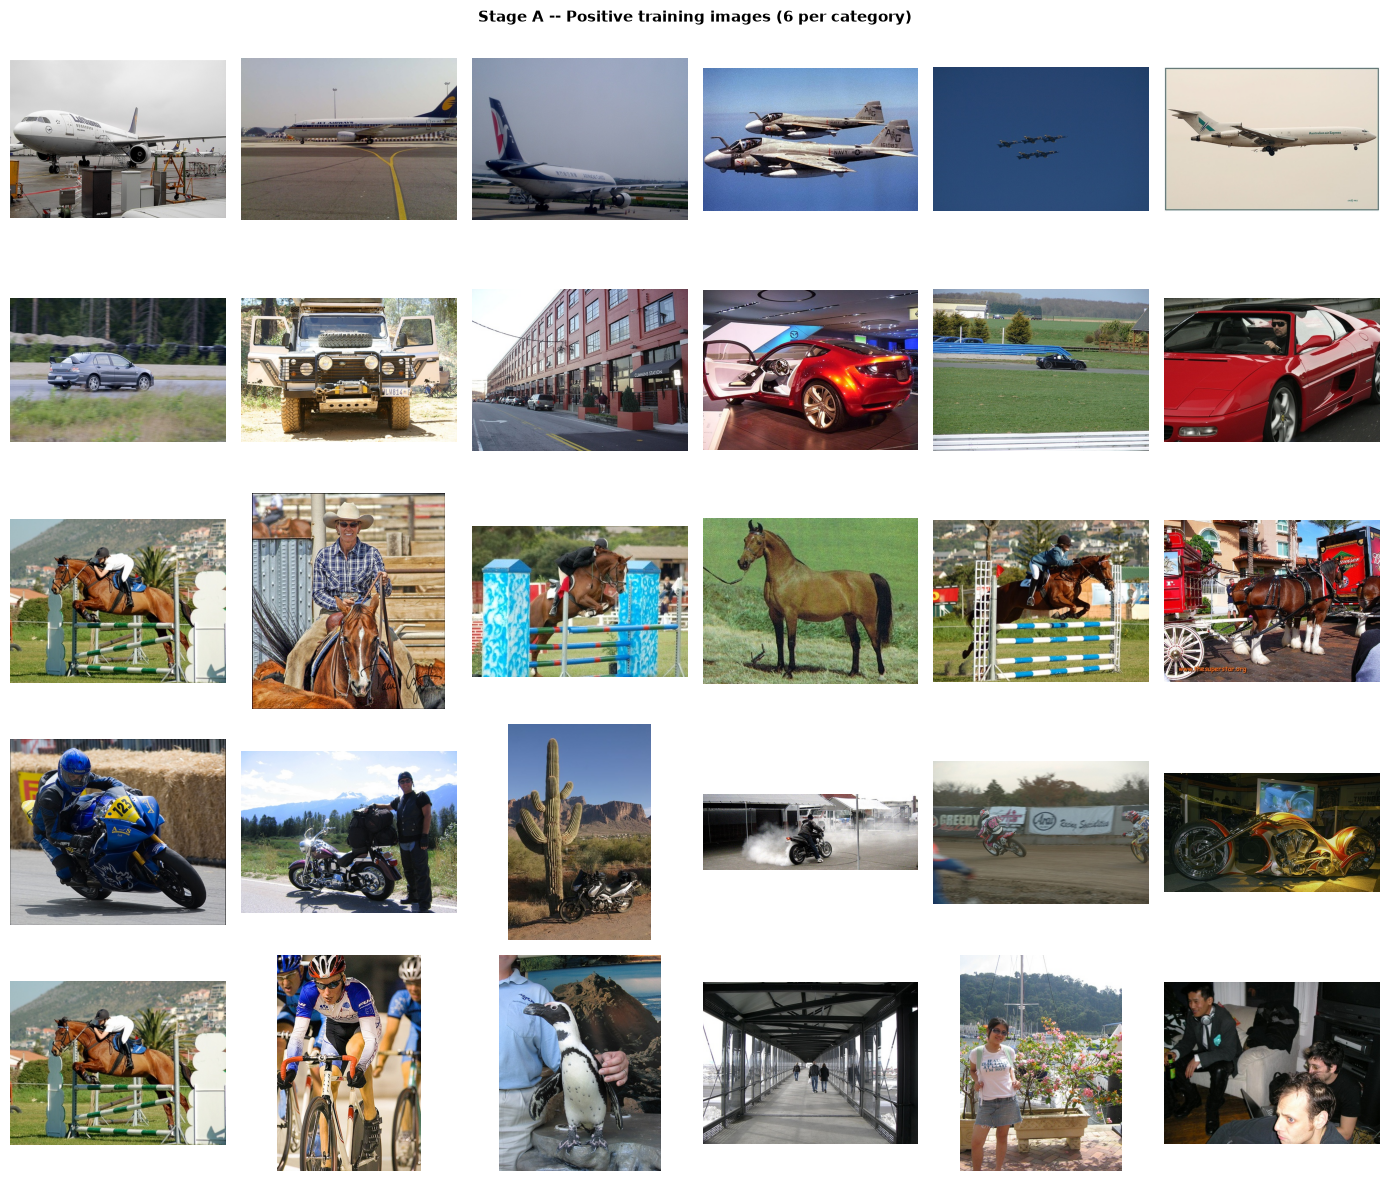

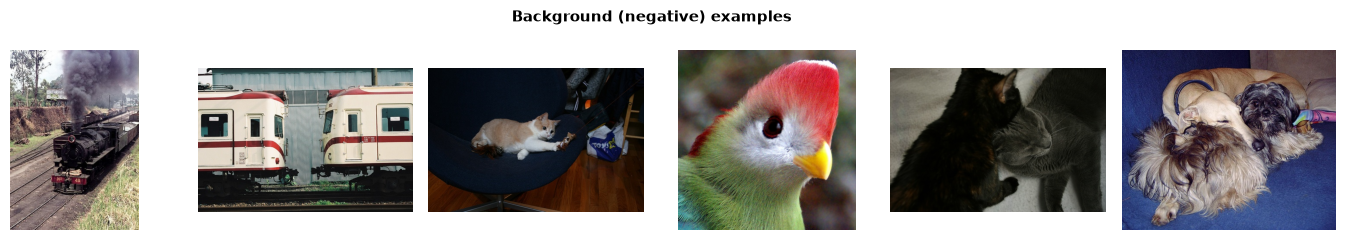

In [4]:
# -- Stage A: visual inspection of representative training images -------------
n_show = 6
cats_grid = CATEGORIES

fig, axes = plt.subplots(len(cats_grid), n_show, figsize=(14, len(cats_grid)*2.4))
for row_i, cat in enumerate(cats_grid):
    _, y_c, names_c = load_enc(cat, enc_512, 'train')
    pos_names = [n for n, y in zip(names_c, y_c) if y > 0][:n_show]
    for col_i in range(n_show):
        ax = axes[row_i][col_i]
        if col_i < len(pos_names):
            img = cv2.imread(str(IMG_DIR / f'{pos_names[col_i]}.jpg'))
            if img is not None:
                ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.axis('off')
    axes[row_i][0].set_ylabel(cat, fontsize=9, rotation=0,
                               ha='right', va='center', labelpad=45)
fig.suptitle('Stage A -- Positive training images (6 per category)', fontsize=11,
             fontweight='bold')
plt.tight_layout(); plt.show()

# Background (negative) examples
neg_names = [n for n, y in zip(names_tr, y_tr) if y < 0][:n_show]
fig2, axes2 = plt.subplots(1, n_show, figsize=(14, 2.4))
for col_i, name in enumerate(neg_names):
    img = cv2.imread(str(IMG_DIR / f'{name}.jpg'))
    if img is not None:
        axes2[col_i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes2[col_i].axis('off')
fig2.suptitle('Background (negative) examples', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()


### Stage B — SVM Parameter Selection

Sweep C ∈ {0.001, 0.01, 0.1, 1, 10, 100} on **motorbike** with 2×2 tiling and L2 normalisation.

C sweep  (motorbike, bovw_K512_C0, L2-norm, 2x2 tiling):
         C  AP val
     0.001  0.1880
     0.010  0.1589
     0.100  0.4718
     1.000  0.5436
    10.000  0.5549  <- best
   100.000  0.5524


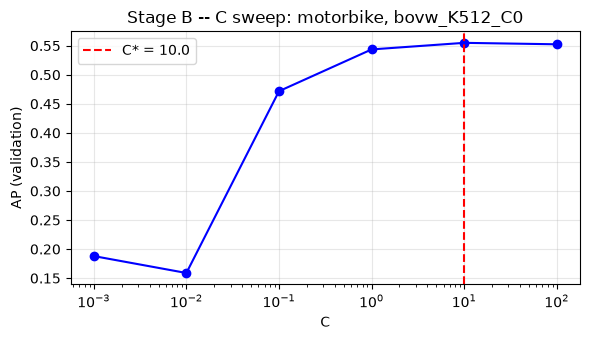


Best C = 10.0

Ranked TRAINING images (motorbike, best C, L2-norm):


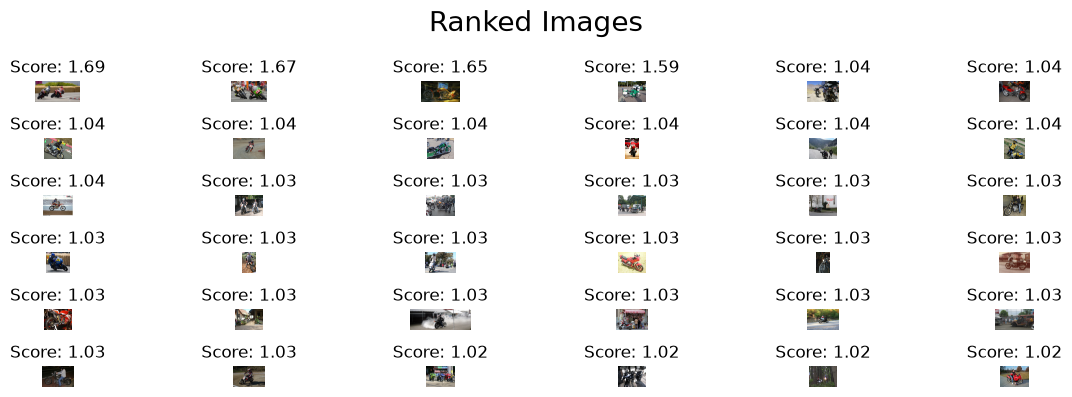

In [5]:
# -- Stage B -- C sweep on validation + inspect ranked training images --------
c_res_512, _, _ = sweep_c(x_tr, y_tr, x_val, y_val, C_VALUES, transform=l2norm)
best_C_512 = best_c(c_res_512)

print('C sweep  (motorbike, bovw_K512_C0, L2-norm, 2x2 tiling):')
print(f'{"C":>10}  AP val')
for C in C_VALUES:
    mark = '  <- best' if C == best_C_512 else ''
    print(f'  {C:8.3f}  {c_res_512[C]:.4f}{mark}')

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogx(C_VALUES, [c_res_512[c] for c in C_VALUES], 'bo-', ms=6)
ax.axvline(best_C_512, color='r', ls='--', label=f'C* = {best_C_512}')
ax.set_xlabel('C'); ax.set_ylabel('AP (validation)')
ax.set_title('Stage B -- C sweep: motorbike, bovw_K512_C0')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f'\nBest C = {best_C_512}')

# Inspect ranked training images (required by Stage B)
W_b, b_b = utils.train_svm(l2norm(x_tr), y_tr, C=best_C_512, seed=SEED)
train_scores = W_b @ l2norm(x_tr).T + b_b
train_paths  = [str(IMG_DIR / f'{n}.jpg') for n in names_tr]
print('\nRanked TRAINING images (motorbike, best C, L2-norm):')
displayRankedImageList(train_scores, train_paths, uniform=False, figzize=(12, 4))


### Stage C — Global Histogram vs 2×2 Spatial Tiling

- **Global**: single histogram → K dim  
- **2×2 tiling**: per-quadrant histogram → 4K dim  

`removeSpatialInformation` averages the 4 tiles to obtain the global representation.

Global  (K=512,  512-dim): AP = 0.4549  C* = 10.0
Tiling  (K=512, 2048-dim): AP = 0.5549  C* = 10.0
Tiling gain: +10.0 p.p.


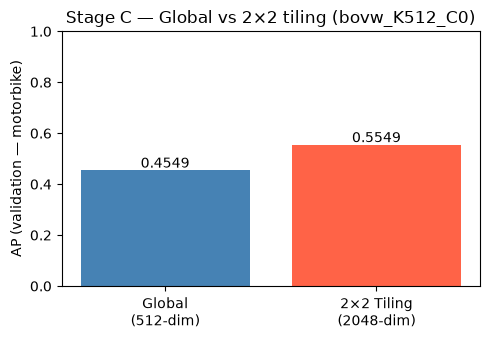

In [6]:
# ── Stage C — Global vs 2×2 spatial tiling ───────────────────────────────────
x_tr_g  = encoders.removeSpatialInformation(x_tr)
x_val_g = encoders.removeSpatialInformation(x_val)

res_global, _, _ = sweep_c(x_tr_g, y_tr, x_val_g, y_val)
res_tiling, _, _ = sweep_c(x_tr,   y_tr, x_val,   y_val)

C_g  = best_c(res_global); ap_g = res_global[C_g]
C_t  = best_c(res_tiling); ap_t = res_tiling[C_t]

print(f'Global  (K=512,  512-dim): AP = {ap_g:.4f}  C* = {C_g}')
print(f'Tiling  (K=512, 2048-dim): AP = {ap_t:.4f}  C* = {C_t}')
print(f'Tiling gain: {(ap_t-ap_g)*100:+.1f} p.p.')

fig, ax = plt.subplots(figsize=(5, 3.5))
labels_bar = ['Global\n(512-dim)', '2×2 Tiling\n(2048-dim)']
vals_bar   = [ap_g, ap_t]
bars = ax.bar(labels_bar, vals_bar, color=['steelblue', 'tomato'])
ax.set_ylabel('AP (validation — motorbike)'); ax.set_ylim(0, 1)
ax.set_title('Stage C — Global vs 2×2 tiling (bovw_K512_C0)')
for bar, v in zip(bars, vals_bar):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.01,
            f'{v:.4f}', ha='center', fontsize=10)
plt.tight_layout(); plt.show()

### Stage E_norm — Normalisation and Hellinger Comparison

Compare four normalisation strategies on the motorbike validation set (K=512, 2×2 tiling).
The **Hellinger kernel** is implemented as a feature map: L1-norm → sqrt → L2-norm.

Normalisation comparison -- motorbike, bovw_K512_C0, 2x2 tiling, val:
Transform                   AP val   C*
------------------------------------------------
  No norm                 : 0.5606   C=0.001
  L1 norm                 : 0.4668   C=1.0
  L2 norm                 : 0.5549   C=10.0
  Hellinger (sqrt+L2)     : 0.7628   C=1.0

Best normalisation: Hellinger (sqrt+L2)


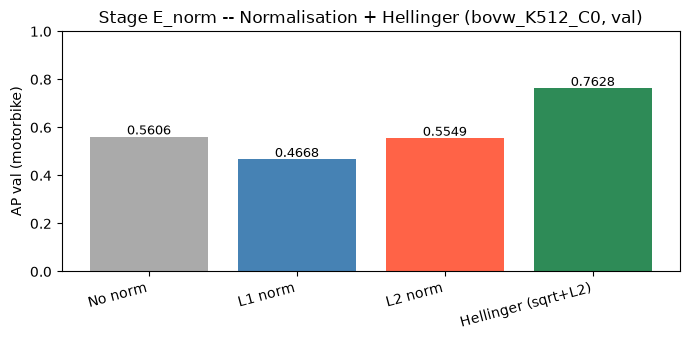

In [7]:
# -- Stage E_norm: normalisation comparison ----------------------------------
_TRANSFORMS = [
    ('No norm',             lambda x: x),
    ('L1 norm',             l1norm),
    ('L2 norm',             l2norm),
    ('Hellinger (sqrt+L2)', hellinger),
]

print('Normalisation comparison -- motorbike, bovw_K512_C0, 2x2 tiling, val:')
print(f'{"Transform":26s}  AP val   C*')
print('-' * 48)
norm_results = {}
for name, tf in _TRANSFORMS:
    res, _, _ = sweep_c(x_tr, y_tr, x_val, y_val, transform=tf)
    C_best = best_c(res)
    norm_results[name] = {'ap': res[C_best], 'C': C_best}
    print(f'  {name:24s}: {res[C_best]:.4f}   C={C_best}')

best_norm_name      = max(norm_results, key=lambda n: norm_results[n]['ap'])
best_norm_transform = dict(_TRANSFORMS)[best_norm_name]
print(f'\nBest normalisation: {best_norm_name}')

fig, ax = plt.subplots(figsize=(7, 3.5))
names_plt = [n for n, _ in _TRANSFORMS]
aps_plt   = [norm_results[n]['ap'] for n in names_plt]
colors_n  = ['#aaaaaa', 'steelblue', 'tomato', 'seagreen']
bars = ax.bar(names_plt, aps_plt, color=colors_n)
ax.set_ylabel('AP val (motorbike)'); ax.set_ylim(0, 1)
ax.set_title('Stage E_norm -- Normalisation + Hellinger (bovw_K512_C0, val)')
for bar, v in zip(bars, aps_plt):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.01,
            f'{v:.4f}', ha='center', fontsize=9)
plt.xticks(rotation=15, ha='right'); plt.tight_layout(); plt.show()


### Stage G_fracs — Vary Number of Training Images

Train with 10%, 25%, 50% and 100% of labelled motorbike training data (stratified).
Repeat with 3 random seeds; report mean ± std AP on validation.


-- L2 norm --
   10%  n=  91: 0.2744 +/- 0.0301
   25%  n= 227: 0.3942 +/- 0.0549
   50%  n= 455: 0.4483 +/- 0.0807
  100%  n= 911: 0.5567 +/- 0.0014

-- Hellinger --
   10%  n=  91: 0.3374 +/- 0.0145
   25%  n= 227: 0.5029 +/- 0.0393
   50%  n= 455: 0.6385 +/- 0.0560
  100%  n= 911: 0.6836 +/- 0.0004


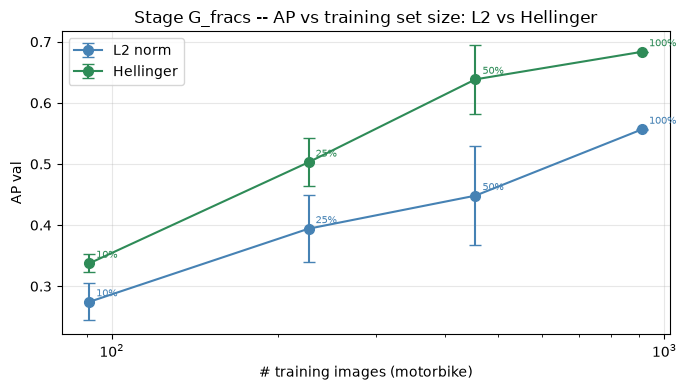

In [8]:
# -- Stage G_fracs: training set size study (L2 norm vs Hellinger) -----------
FRACS    = [0.10, 0.25, 0.50, 1.00]
SEEDS_FR = [0, 42, 123]

def subsample_stratified(x, y, frac, seed):
    rng     = np.random.RandomState(seed)
    pos_idx = np.where(y > 0)[0]
    neg_idx = np.where(y < 0)[0]
    sel = np.concatenate([
        rng.choice(pos_idx, max(1, int(len(pos_idx) * frac)), replace=False),
        rng.choice(neg_idx, max(1, int(len(neg_idx) * frac)), replace=False),
    ])
    return x[sel], y[sel]

_FRAC_TFS = [('L2 norm', l2norm), ('Hellinger', hellinger)]
frac_results_all = {}

for tf_name, tf in _FRAC_TFS:
    print(f'\n-- {tf_name} --')
    fr = {}
    for frac in FRACS:
        seed_aps = []
        for s in SEEDS_FR:
            x_sub, y_sub = subsample_stratified(x_tr, y_tr, frac, s)
            W, b = utils.train_svm(tf(x_sub), y_sub, C=best_C_512, seed=s)
            seed_aps.append(compute_ap(y_val, W @ tf(x_val).T + b))
        n_imgs = int(len(y_tr) * frac)
        fr[frac] = {'n': n_imgs, 'mean': float(np.mean(seed_aps)),
                    'std': float(np.std(seed_aps))}
        print(f'  {int(frac*100):3d}%  n={n_imgs:4d}: '
              f'{fr[frac]["mean"]:.4f} +/- {fr[frac]["std"]:.4f}')
    frac_results_all[tf_name] = fr

# Keep best-norm fracs under original name for downstream use
frac_results = frac_results_all[best_norm_name] \
    if best_norm_name in frac_results_all else \
    frac_results_all['Hellinger']

colors_fr = {'L2 norm': 'steelblue', 'Hellinger': 'seagreen'}
fig, ax = plt.subplots(figsize=(7, 4))
for tf_name, _ in _FRAC_TFS:
    ns   = [frac_results_all[tf_name][f]['n']    for f in FRACS]
    mns  = [frac_results_all[tf_name][f]['mean'] for f in FRACS]
    stds = [frac_results_all[tf_name][f]['std']  for f in FRACS]
    ax.errorbar(ns, mns, yerr=stds, fmt='o-', ms=7, capsize=4,
                elinewidth=1.5, color=colors_fr[tf_name], label=tf_name)
    for frac_val, n, m in zip(FRACS, ns, mns):
        ax.annotate(f'{int(frac_val*100)}%', (n, m),
                    xytext=(5, 4), textcoords='offset points', fontsize=7,
                    color=colors_fr[tf_name])
ax.set_xlabel('# training images (motorbike)')
ax.set_ylabel('AP val')
ax.set_title('Stage G_fracs -- AP vs training set size: L2 vs Hellinger')
ax.set_xscale('log'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### Stage D — Vocabulary Size Study

Compare K ∈ {256, 512, 1024}. Encoders for K=256 and K=1024 are trained on the fly if not present (direct Python calls, no subprocess).


──────────────────────────────────────────────────
K = 256
  bovw_K256_C0: already exists.
  Dim = 1024   AP_val = 0.5901   C* = 1.0

──────────────────────────────────────────────────
K = 512
  Dim = 2048   AP_val = 0.5549   C* = 10.0

──────────────────────────────────────────────────
K = 1024
  bovw_K1024_C0: already exists.
  Dim = 4096   AP_val = 0.5100   C* = 10.0




,Dim (tiling),AP val (motorbike),C*
K,,,
256,1024,0.5901,1.0
512,2048,0.5549,10.0
1024,4096,0.5100,10.0


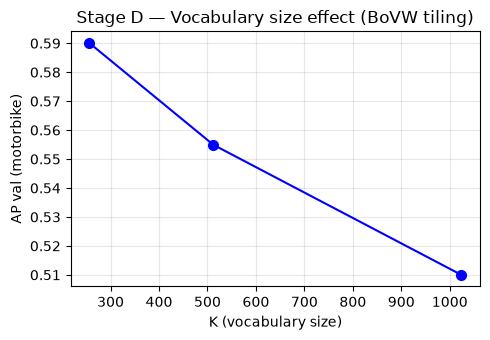

In [9]:
# ── Stage D — Vocabulary size K = 256 / 512 / 1024 ───────────────────────────
K_VALUES  = [256, 512, 1024]
k_results = {}

for k in K_VALUES:
    print(f'\n{"─"*50}')
    print(f'K = {k}')
    enc = 'bovw_K512_C0' if k == 512 else ensure_encoding(k)
    x_tr_k, y_tr_k, _   = load_enc('motorbike', enc, 'train')
    x_val_k, y_val_k, _ = load_enc('motorbike', enc, 'val')
    res_k, _, _ = sweep_c(x_tr_k, y_tr_k, x_val_k, y_val_k)
    Ck = best_c(res_k)
    k_results[k] = {'enc': enc, 'ap': res_k[Ck], 'C': Ck,
                    'dim': x_tr_k.shape[1]}
    print(f'  Dim = {x_tr_k.shape[1]}   AP_val = {res_k[Ck]:.4f}   C* = {Ck}')

print('\n')
df_k = pd.DataFrame([
    {'K': k, 'Dim (tiling)': v['dim'],
     'AP val (motorbike)': f"{v['ap']:.4f}", 'C*': v['C']}
    for k, v in k_results.items()
])
display(df_k.set_index('K'))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(K_VALUES, [k_results[k]['ap'] for k in K_VALUES], 'bo-', ms=7)
ax.set_xlabel('K (vocabulary size)'); ax.set_ylabel('AP val (motorbike)')
ax.set_title('Stage D — Vocabulary size effect (BoVW tiling)')
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

#### Stage D_multi — Multi-seed SVM Stability

Vary SVM random seed {0, 42, 123} with encoder fixed.
Reports mean ± std AP on motorbike validation to check result stability across K values.

Multi-seed AP stability -- motorbike, val, 2x2 tiling (3 SVM seeds):


,Mean +/- Std,seed=0,seed=42,seed=123
K,,,,
256,0.5905 +/- 0.0003,0.5906,0.5901,0.5908
512,0.5561 +/- 0.0010,0.5558,0.5549,0.5574
1024,0.5102 +/- 0.0007,0.5111,0.5100,0.5095


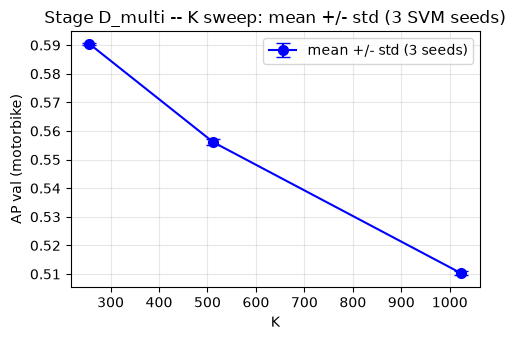

In [10]:
# -- Stage D_multi: multi-seed AP stability ----------------------------------
SEEDS_MULTI = [0, 42, 123]
k_multi = {}
for k in K_VALUES:
    enc_k = 'bovw_K512_C0' if k == 512 else f'bovw_K{k}_C0'
    x_tr_k, y_tr_k, _   = load_enc('motorbike', enc_k, 'train')
    x_val_k, y_val_k, _ = load_enc('motorbike', enc_k, 'val')
    x_tr_n  = l2norm(x_tr_k)
    x_val_n = l2norm(x_val_k)
    seed_aps = []
    for s in SEEDS_MULTI:
        best_ap_s = -1
        for C in C_VALUES:
            W, b = utils.train_svm(x_tr_n, y_tr_k, C=C, seed=s)
            ap_s = compute_ap(y_val_k, W @ x_val_n.T + b)
            if ap_s > best_ap_s:
                best_ap_s = ap_s
        seed_aps.append(best_ap_s)
    k_multi[k] = {'mean': float(np.mean(seed_aps)), 'std': float(np.std(seed_aps)),
                  'per_seed': seed_aps}

df_multi = pd.DataFrame([
    {'K': k,
     'Mean +/- Std': f'{v["mean"]:.4f} +/- {v["std"]:.4f}',
     **{f'seed={s}': f'{v["per_seed"][i]:.4f}' for i, s in enumerate(SEEDS_MULTI)}}
    for k, v in k_multi.items()
])
print('Multi-seed AP stability -- motorbike, val, 2x2 tiling (3 SVM seeds):')
display(df_multi.set_index('K'))

fig, ax = plt.subplots(figsize=(5, 3.5))
means = [k_multi[k]['mean'] for k in K_VALUES]
stds  = [k_multi[k]['std']  for k in K_VALUES]
ax.errorbar(K_VALUES, means, yerr=stds, fmt='bo-', ms=7, capsize=5,
            elinewidth=1.5, label='mean +/- std (3 seeds)')
ax.set_xlabel('K'); ax.set_ylabel('AP val (motorbike)')
ax.set_title('Stage D_multi -- K sweep: mean +/- std (3 SVM seeds)')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()


### Stage E — BoVW Classification Results

PR curves, AP per category, mAP, P@K and R@K using the best K found in Stage D.

Best config (val): bovw_K256_C0, 2x2 tiling, C=1.0, norm=Hellinger (sqrt+L2)

Category        AP (test)
----------------------------
  aeroplane   : 0.6991
  car         : 0.7298
  horse       : 0.6426
  motorbike   : 0.6078
  person      : 0.7682
  mAP         : 0.6895


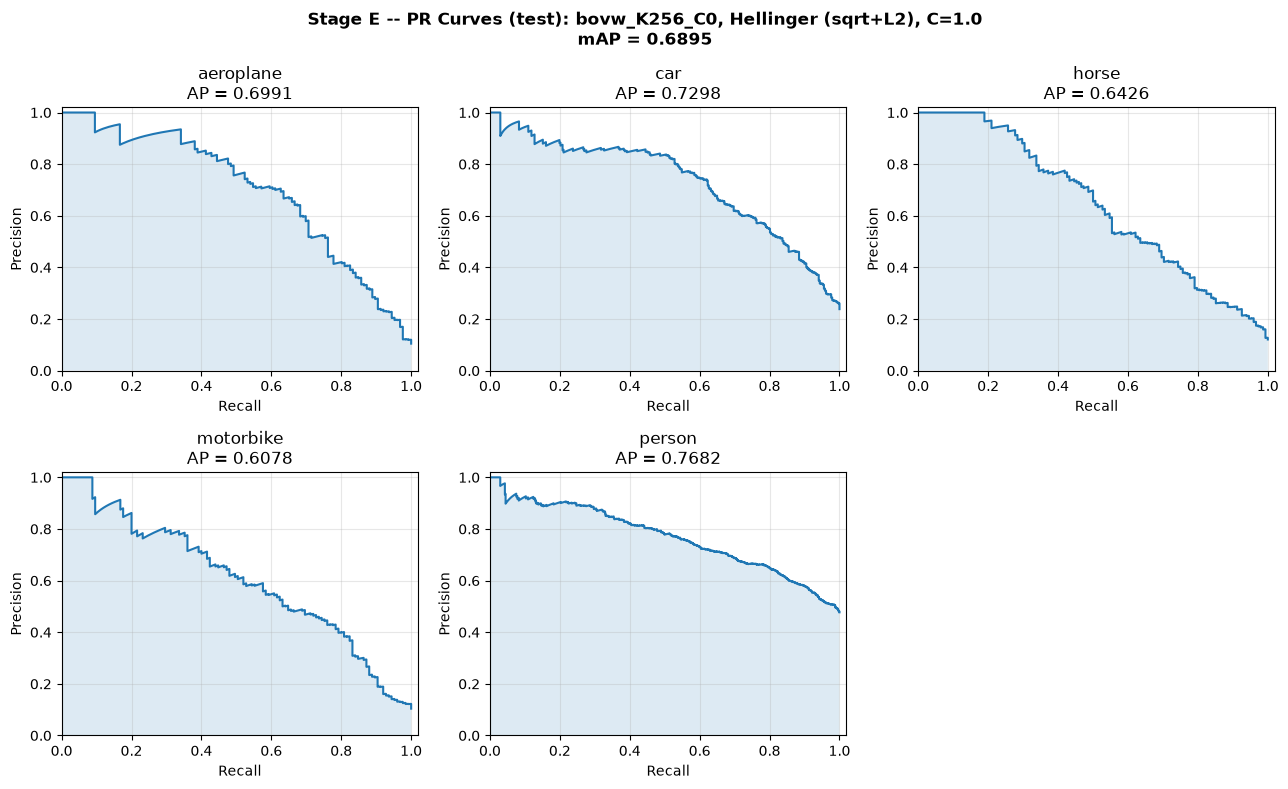


P@K and R@K -- motorbike (test):
  K=  5: P@K = 1.0000  R@K = 0.0400
  K= 10: P@K = 1.0000  R@K = 0.0800
  K= 20: P@K = 0.9000  R@K = 0.1440


In [11]:
# -- Stage E: final evaluation on test set (best K, best C, best norm) ------
best_K   = max(k_results, key=lambda k: k_results[k]['ap'])
best_enc = k_results[best_K]['enc']
best_C   = k_results[best_K]['C']
print(f'Best config (val): {best_enc}, 2x2 tiling, C={best_C}, norm={best_norm_name}\n')

ap_bovw, svms_bovw = eval_all_cats(best_enc, best_C,
                                   transform=best_norm_transform)

print(f'{"Category":14s}  AP (test)')
print('-' * 28)
for cat, ap in ap_bovw.items():
    print(f'  {cat:12s}: {ap:.4f}')

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes_flat = axes.flatten()
for i, cat in enumerate(CATEGORIES):
    svm = svms_bovw[cat]
    prec, rec, _ = precision_recall_curve(svm['y_val'], svm['scores'])
    axes_flat[i].plot(rec, prec, lw=1.5)
    axes_flat[i].fill_between(rec, prec, alpha=0.15)
    axes_flat[i].set_title(f'{cat}\nAP = {ap_bovw[cat]:.4f}')
    axes_flat[i].set_xlabel('Recall'); axes_flat[i].set_ylabel('Precision')
    axes_flat[i].set_ylim(0, 1.02); axes_flat[i].set_xlim(0, 1.02)
    axes_flat[i].grid(alpha=0.3)
axes_flat[-1].axis('off')
fig.suptitle(
    f'Stage E -- PR Curves (test): {best_enc}, {best_norm_name}, C={best_C}'
    f'\nmAP = {ap_bovw["mAP"]:.4f}',
    fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

svm_mot = svms_bovw['motorbike']
print('\nP@K and R@K -- motorbike (test):')
for k in [5, 10, 20]:
    pk = compute_pk(svm_mot['y_val'], svm_mot['scores'], k)
    rk = compute_rk(svm_mot['y_val'], svm_mot['scores'], k)
    print(f'  K={k:3d}: P@K = {pk:.4f}  R@K = {rk:.4f}')


#### Stage E_cm — Confusion Matrices at Threshold = 0

Classify each test image positive if SVM score ≥ 0.
Reports TP/FP/TN/FN and precision/recall per category.

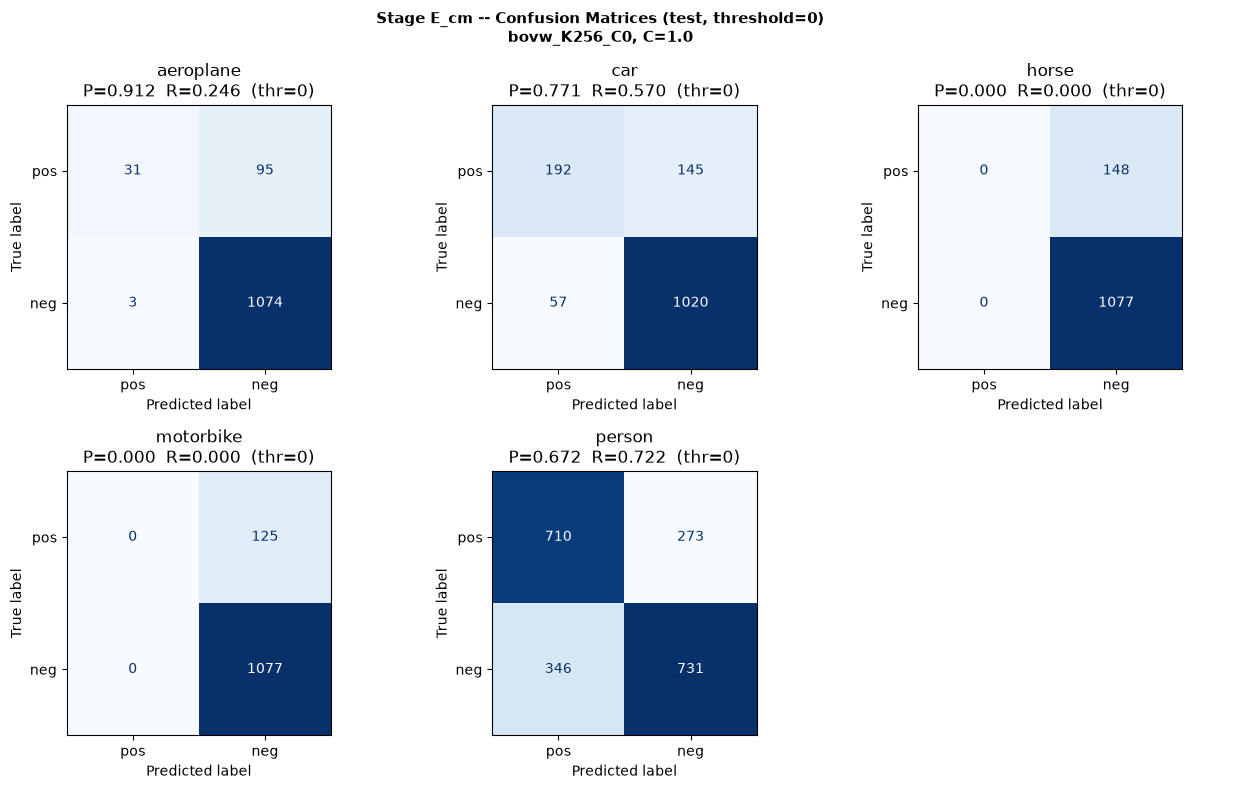


Precision and Recall at threshold=0 (test set):


,TP,FN,FP,TN,Precision,Recall
Category,,,,,,
aeroplane,31,95,3,1074,0.9118,0.2460
car,192,145,57,1020,0.7711,0.5697
horse,0,148,0,1077,0.0000,0.0000
motorbike,0,125,0,1077,0.0000,0.0000
person,710,273,346,731,0.6723,0.7223


In [12]:
# -- Stage E_cm: confusion matrices at threshold=0 (test) -------------------
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes_flat = axes.flatten()
cm_rows = []
for i, cat in enumerate(CATEGORIES):
    svm    = svms_bovw[cat]
    y_true = svm['y_val']
    y_pred = np.where(svm['scores'] >= 0, 1, -1)
    cm = confusion_matrix(y_true, y_pred, labels=[1, -1])
    tp, fn = cm[0, 0], cm[0, 1]
    fp, tn = cm[1, 0], cm[1, 1]
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    disp = ConfusionMatrixDisplay(cm, display_labels=['pos', 'neg'])
    disp.plot(ax=axes_flat[i], colorbar=False, cmap='Blues')
    axes_flat[i].set_title(f'{cat}\nP={prec:.3f}  R={rec:.3f}  (thr=0)')
    cm_rows.append({'Category': cat, 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn,
                    'Precision': f'{prec:.4f}', 'Recall': f'{rec:.4f}'})

axes_flat[-1].axis('off')
fig.suptitle(f'Stage E_cm -- Confusion Matrices (test, threshold=0)\n{best_enc}, C={best_C}',
             fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()
print('\nPrecision and Recall at threshold=0 (test set):')
display(pd.DataFrame(cm_rows).set_index('Category'))


### Stage F — Ranked Retrieval and Relevant Visual Words

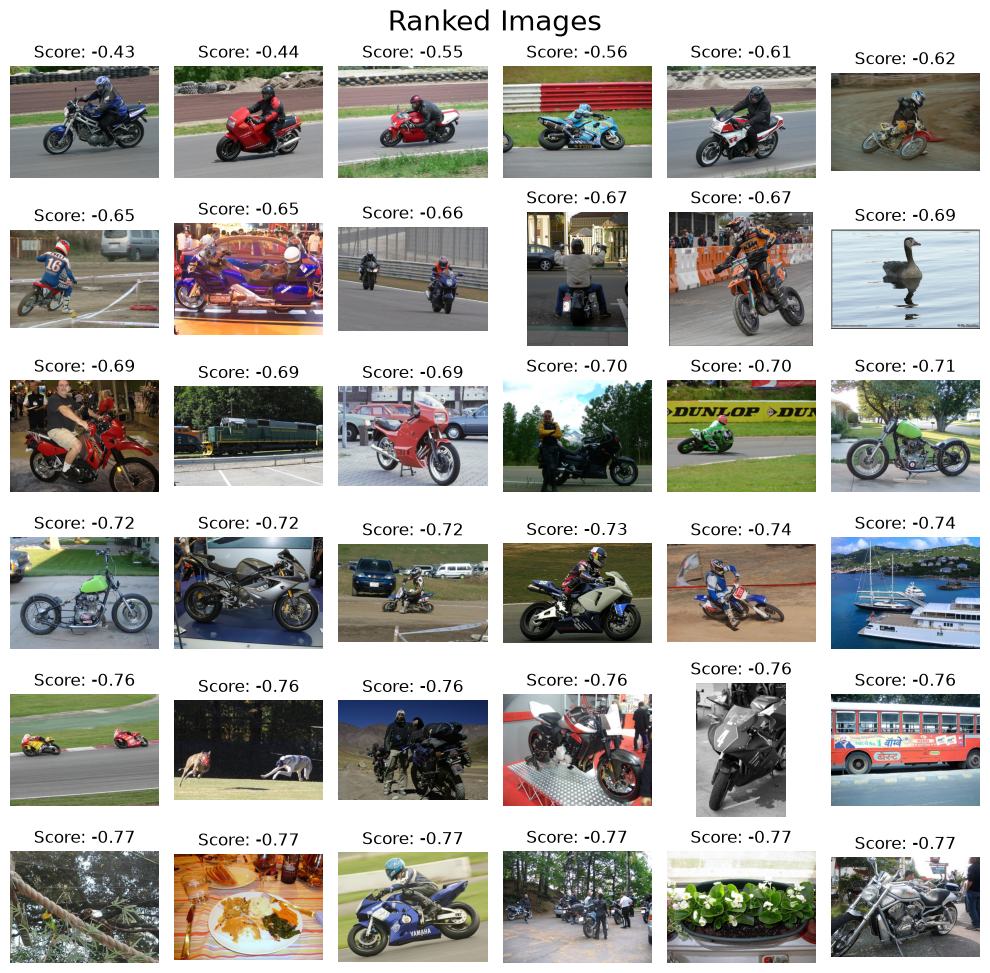

In [13]:
# ── Stage F — Ranked image list ───────────────────────────────────────────────
svm = svms_bovw['motorbike']
full_paths = [str(IMG_DIR / f'{n}.jpg') for n in svm['names']]
displayRankedImageList(svm['scores'], full_paths, uniform=False, figzize=(10, 10))

In [14]:
# ── Stage F — Relevant visual words ──────────────────────────────────────────
assert 'bovw' in best_enc, 'Relevant visual words only available for BoVW'
encoder_obj = encoders.ImageEncoder(str(ENC_DIR / f'{best_enc}.npz'))

svm = svms_bovw['motorbike']
max_idx  = np.argmax(svm['scores'])
img_name = svm['names'][max_idx]
img_file = str(IMG_DIR / f'{img_name}.jpg')
print(f'Selected image: {img_name}  (score = {svm["scores"][max_idx]:.4f})')

img = encoders.standarizeImage(img_file)
rvw = RelevantVisualWordsDisplay(img, svm['W'], encoder_obj)

import ipywidgets as widgets
@widgets.interact(rank=(0, min(len(rvw)-1, 19)))
def display_rvw(rank=0):
    rvw.plot(rank, figsize=(12, 8))

Selected image: 009781  (score = -0.4280)
Number of keypoints: 41771 Descriptor dimension: 128


interactive(children=(IntSlider(value=0, description='rank', max=19), Output()), _dom_classes=('widget-interac…

---
## Part 2 — VLAD and Fisher Vector

- **VLAD** (K=32, PCA=80): residuals per centroid → dim = K × C = **2 560**  
- **Fisher Vector** (K=32, PCA=80): 1st and 2nd order GMM statistics → dim = 2KC = **5 120**

### Stage G — VLAD Encoding

In [15]:
# ── Stage G — VLAD ────────────────────────────────────────────────────────────
enc_vlad = 'vlad_K32_C80'

x_tr_v, y_tr_v, _   = load_enc('motorbike', enc_vlad, 'train')
x_val_v, y_val_v, _ = load_enc('motorbike', enc_vlad, 'val')
print(f'VLAD dimension: {x_tr_v.shape[1]}  (= 32 × 80)')

# C selected on validation
c_res_vlad, _, _ = sweep_c(x_tr_v, y_tr_v, x_val_v, y_val_v)
best_C_vlad = best_c(c_res_vlad)
print(f'Best C = {best_C_vlad}   AP val (motorbike) = {c_res_vlad[best_C_vlad]:.4f}')

# Final evaluation on test
ap_vlad, svms_vlad = eval_all_cats(enc_vlad, best_C_vlad)  # subset='test'
print(f'\nAP per category (VLAD, C={best_C_vlad}, test):')
for cat, ap in ap_vlad.items():
    print(f'  {cat:12s}: {ap:.4f}')

VLAD dimension: 10240  (= 32 × 80)
Best C = 1.0   AP val (motorbike) = 0.7194

AP per category (VLAD, C=1.0, test):
  aeroplane   : 0.7482
  car         : 0.7656
  horse       : 0.6781
  motorbike   : 0.6902
  person      : 0.7761
  mAP         : 0.7316


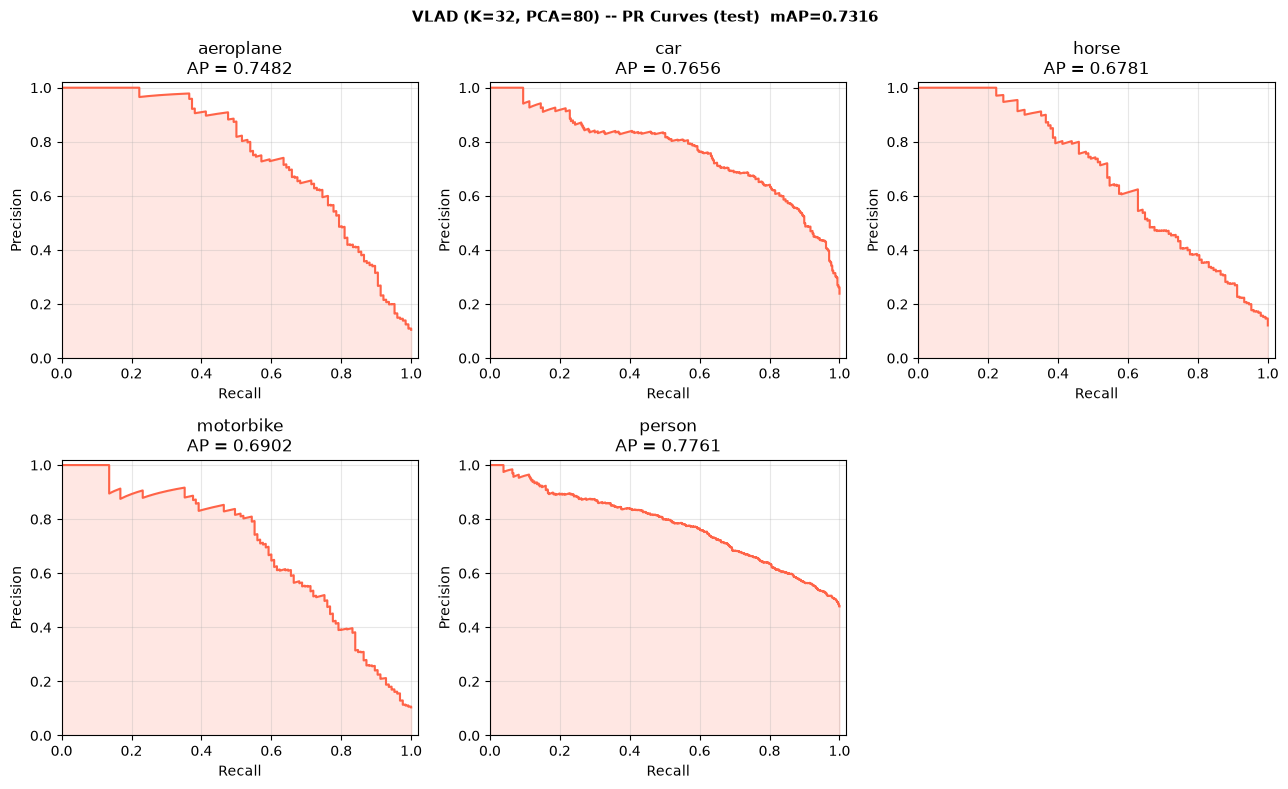

Ranked test images -- motorbike (VLAD K=32 PCA=80):


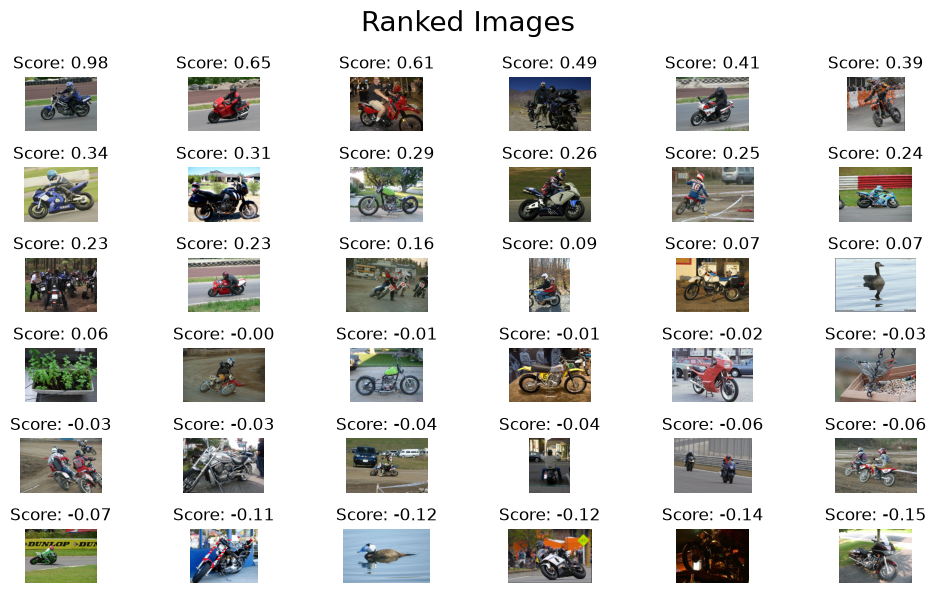

In [16]:
# -- Stage G (VLAD): PR curves + ranked retrieval (motorbike test) -----------
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes_flat = axes.flatten()
for i, cat in enumerate(CATEGORIES):
    svm = svms_vlad[cat]
    prec, rec, _ = precision_recall_curve(svm['y_val'], svm['scores'])
    axes_flat[i].plot(rec, prec, lw=1.5, color='tomato')
    axes_flat[i].fill_between(rec, prec, alpha=0.15, color='tomato')
    axes_flat[i].set_title(f'{cat}\nAP = {ap_vlad[cat]:.4f}')
    axes_flat[i].set_xlabel('Recall'); axes_flat[i].set_ylabel('Precision')
    axes_flat[i].set_ylim(0, 1.02); axes_flat[i].set_xlim(0, 1.02)
    axes_flat[i].grid(alpha=0.3)
axes_flat[-1].axis('off')
fig.suptitle(f'VLAD (K=32, PCA=80) -- PR Curves (test)  mAP={ap_vlad["mAP"]:.4f}',
             fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

# Ranked test images -- motorbike
svm_v = svms_vlad['motorbike']
paths_v = [str(IMG_DIR / f'{n}.jpg') for n in svm_v['names']]
print('Ranked test images -- motorbike (VLAD K=32 PCA=80):')
displayRankedImageList(svm_v['scores'], paths_v, uniform=False, figzize=(10, 6))


### Stage H — Fisher Vector Encoding

In [17]:
# ── Stage H — Fisher Vector ───────────────────────────────────────────────────
enc_fv = 'fv_K32_C80'

x_tr_f, y_tr_f, _   = load_enc('motorbike', enc_fv, 'train')
x_val_f, y_val_f, _ = load_enc('motorbike', enc_fv, 'val')
print(f'FV dimension: {x_tr_f.shape[1]}  (= 2 × 32 × 80)')

# C selected on validation
c_res_fv, _, _ = sweep_c(x_tr_f, y_tr_f, x_val_f, y_val_f)
best_C_fv = best_c(c_res_fv)
print(f'Best C = {best_C_fv}   AP val (motorbike) = {c_res_fv[best_C_fv]:.4f}')

# Final evaluation on test
ap_fv, svms_fv = eval_all_cats(enc_fv, best_C_fv)  # subset='test'
print(f'\nAP per category (FV, C={best_C_fv}, test):')
for cat, ap in ap_fv.items():
    print(f'  {cat:12s}: {ap:.4f}')

FV dimension: 20608  (= 2 × 32 × 80)
Best C = 10.0   AP val (motorbike) = 0.7300

AP per category (FV, C=10.0, test):
  aeroplane   : 0.7113
  car         : 0.7581
  horse       : 0.6387
  motorbike   : 0.6754
  person      : 0.7617
  mAP         : 0.7090


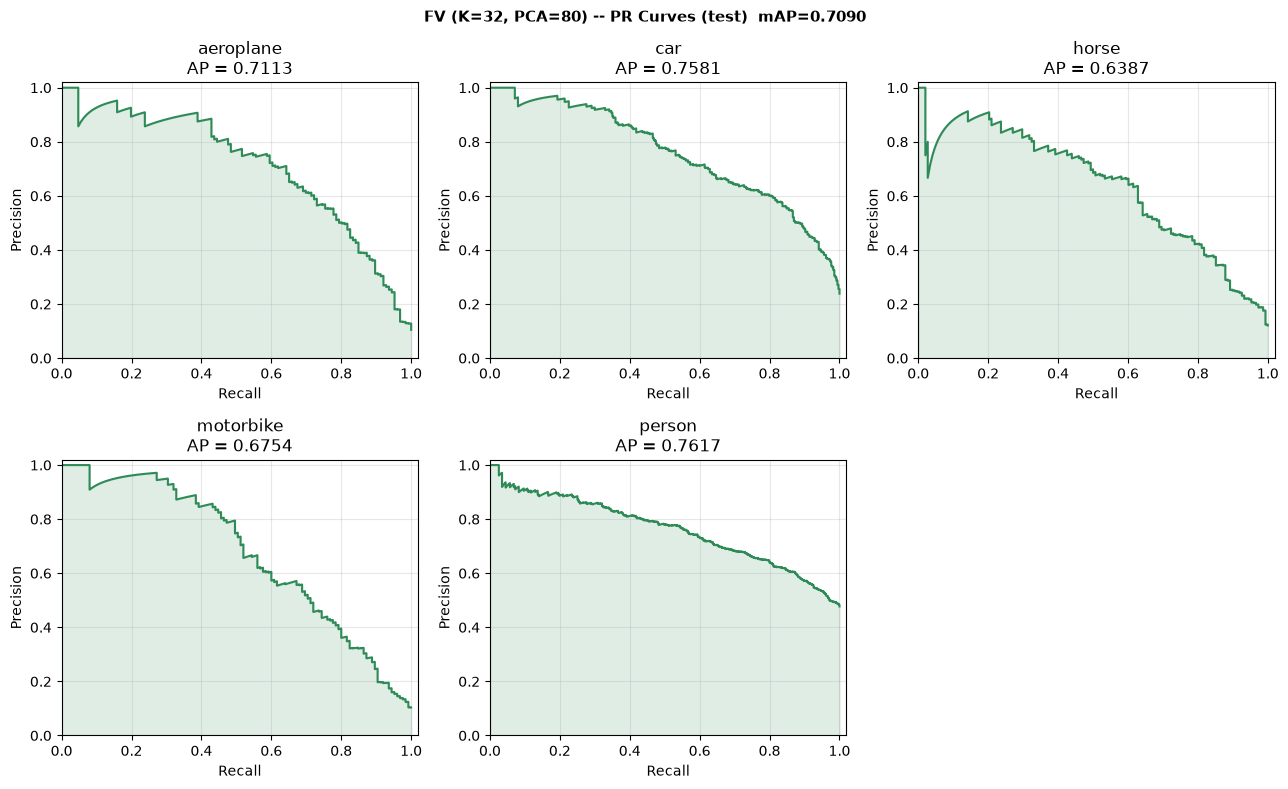

Ranked test images -- motorbike (FV K=32 PCA=80):


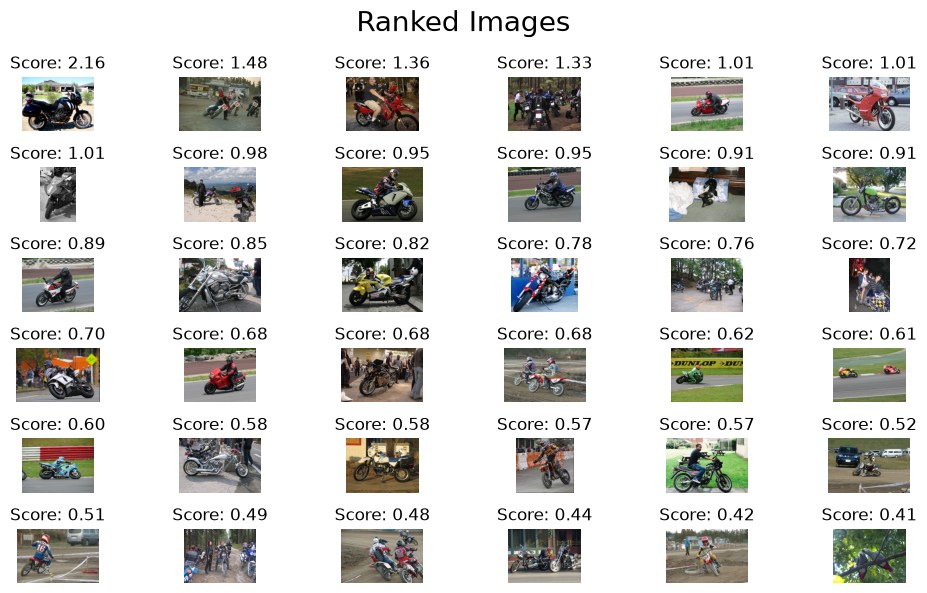

In [18]:
# -- Stage H (FV): PR curves + ranked retrieval (motorbike test) -------------
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes_flat = axes.flatten()
for i, cat in enumerate(CATEGORIES):
    svm = svms_fv[cat]
    prec, rec, _ = precision_recall_curve(svm['y_val'], svm['scores'])
    axes_flat[i].plot(rec, prec, lw=1.5, color='seagreen')
    axes_flat[i].fill_between(rec, prec, alpha=0.15, color='seagreen')
    axes_flat[i].set_title(f'{cat}\nAP = {ap_fv[cat]:.4f}')
    axes_flat[i].set_xlabel('Recall'); axes_flat[i].set_ylabel('Precision')
    axes_flat[i].set_ylim(0, 1.02); axes_flat[i].set_xlim(0, 1.02)
    axes_flat[i].grid(alpha=0.3)
axes_flat[-1].axis('off')
fig.suptitle(f'FV (K=32, PCA=80) -- PR Curves (test)  mAP={ap_fv["mAP"]:.4f}',
             fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

svm_f = svms_fv['motorbike']
paths_f = [str(IMG_DIR / f'{n}.jpg') for n in svm_f['names']]
print('Ranked test images -- motorbike (FV K=32 PCA=80):')
displayRankedImageList(svm_f['scores'], paths_f, uniform=False, figzize=(10, 6))


### Stage I — Method Comparison: BoVW vs VLAD vs FV

Stage I -- AP per category and mAP (test):


,Dim,aeroplane,car,horse,motorbike,person,mAP
Method,,,,,,,
BoVW K=256 tiling,1024,0.6991,0.7298,0.6426,0.6078,0.7682,0.6895
VLAD K=32 PCA=80,10240,0.7482,0.7656,0.6781,0.6902,0.7761,0.7316
FV K=32 PCA=80,20608,0.7113,0.7581,0.6387,0.6754,0.7617,0.7090


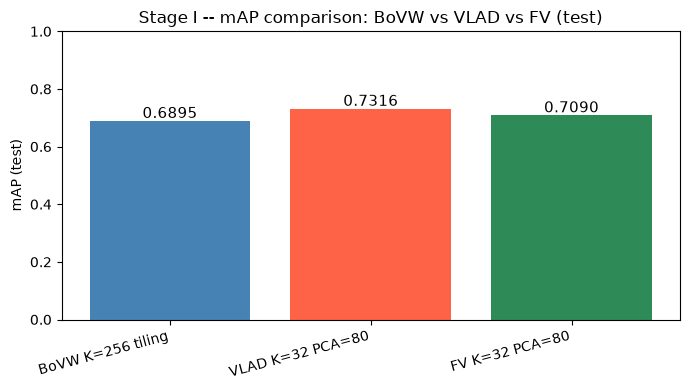


Timings and storage (5 OvR classifiers, test set):


,Dim,SVM train (s),Inference (s),Storage (MB)
Method,,,,
BoVW K=256 tiling,1024,0.143,0.0020,7.8
VLAD K=32 PCA=80,10240,2.128,0.7188,209.1
FV K=32 PCA=80,20608,13.351,0.0255,879.2


In [19]:
# -- Stage I: comparison table BoVW vs VLAD vs FV (test) --------------------
method_info = {
    f'BoVW K={best_K} tiling': {
        'dim': k_results[best_K]['dim'], 'aps': ap_bovw,
        'svms': svms_bovw, 'enc': best_enc},
    'VLAD K=32 PCA=80': {
        'dim': x_tr_v.shape[1], 'aps': ap_vlad,
        'svms': svms_vlad, 'enc': enc_vlad},
    'FV K=32 PCA=80': {
        'dim': x_tr_f.shape[1], 'aps': ap_fv,
        'svms': svms_fv, 'enc': enc_fv},
}

rows = []
for method, info in method_info.items():
    row = {'Method': method, 'Dim': info['dim']}
    for cat in CATEGORIES:
        row[cat] = f'{info["aps"][cat]:.4f}'
    row['mAP'] = f'{info["aps"]["mAP"]:.4f}'
    rows.append(row)

df_comp = pd.DataFrame(rows).set_index('Method')
print('Stage I -- AP per category and mAP (test):')
display(df_comp)

fig, ax = plt.subplots(figsize=(7, 4))
methods_list = list(method_info.keys())
maps = [method_info[m]['aps']['mAP'] for m in methods_list]
colors = ['steelblue', 'tomato', 'seagreen']
bars = ax.bar(methods_list, maps, color=colors)
ax.set_ylabel('mAP (test)'); ax.set_ylim(0, 1)
ax.set_title('Stage I -- mAP comparison: BoVW vs VLAD vs FV (test)')
for bar, v in zip(bars, maps):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.01,
            f'{v:.4f}', ha='center', fontsize=11)
plt.xticks(rotation=15, ha='right'); plt.tight_layout(); plt.show()

# Timings and storage
timing_rows = []
for method, info in method_info.items():
    svms = info['svms']
    t_train = sum(svms[cat]['t_train'] for cat in CATEGORIES)
    t_infer = sum(svms[cat]['t_infer'] for cat in CATEGORIES)
    smb = storage_mb(info['enc'])
    timing_rows.append({
        'Method':        method,
        'Dim':           info['dim'],
        'SVM train (s)': f'{t_train:.3f}',
        'Inference (s)': f'{t_infer:.4f}',
        'Storage (MB)':  f'{smb:.1f}',
    })

df_timing = pd.DataFrame(timing_rows).set_index('Method')
print('\nTimings and storage (5 OvR classifiers, test set):')
display(df_timing)


---
## Part 3 — Large Vocabulary vs PCA

1. **Vocabulary size K** (BoVW K=256/512/1024)  
2. **PCA compression** — VLAD and FV compress 128→80 dim before aggregation

### Stage J — Large Vocabulary vs PCA — Final Table

In [20]:
# ── Stage J — Vocabulary size effect (BoVW K sweep, val) ─────────────────────
# K was chosen on val — these numbers are for hyperparameter selection only.
print('BoVW — vocabulary size K (motorbike, 2×2 tiling, validation):')
df_k_show = pd.DataFrame([
    {'K': k, 'Dim (tiling)': v['dim'],
     'AP val': f"{v['ap']:.4f}", 'C*': v['C']}
    for k, v in k_results.items()
])
display(df_k_show.set_index('K'))

BoVW — vocabulary size K (motorbike, 2×2 tiling, validation):


,Dim (tiling),AP val,C*
K,,,
256,1024,0.5901,1.0
512,2048,0.5549,10.0
1024,4096,0.5100,10.0


In [21]:
# -- Stage J: large vocabulary vs PCA (Part 3) ------------------------------
# Stability note: PCA fit and SVM training use fixed SEED=42 (not 3 seeds)
# due to computational cost. This is acknowledged as a limitation.
from sklearn.decomposition import PCA as SkPCA
from sklearn.metrics import f1_score

def macro_f1_acc_at0(encoding, C, transform=l2norm, subset='test', pca=None):
    # Returns (macro-F1, macro binary-accuracy) at threshold=0 over all 5 cats.
    all_true, all_pred = [], []
    bin_accs = []
    for cat_i, cat in enumerate(CATEGORIES):
        x_tr_c, y_tr_c, _ = load_enc(cat, encoding, 'train')
        x_te_c, y_te_c, _ = load_enc(cat, encoding, subset)
        if pca is not None:
            x_tr_c = pca.transform(transform(x_tr_c))
            x_te_c = pca.transform(transform(x_te_c))
        else:
            x_tr_c = transform(x_tr_c)
            x_te_c = transform(x_te_c)
        W, b   = utils.train_svm(x_tr_c, y_tr_c, C=C, seed=SEED)
        scores = W @ x_te_c.T + b
        y_pred_bin = np.where(scores >= 0, 1, -1)
        bin_accs.append(float(np.mean(y_pred_bin == y_te_c)))
        all_true.extend([cat_i if y > 0 else -1 for y in y_te_c])
        all_pred.extend([cat_i if s >= 0 else -1 for s in scores])
    f1  = f1_score(all_true, all_pred,
                   labels=list(range(len(CATEGORIES))),
                   average='macro', zero_division=0)
    acc = float(np.mean(bin_accs))
    return f1, acc

enc_1024 = k_results[1024]['enc']

x_tr_all   = np.vstack([load_enc(c, enc_1024, 'train')[0] for c in CATEGORIES])
x_tr_all_n = l2norm(x_tr_all)

pca_dims    = [128, 256]
pca_ap_rows = []

for pca_d in pca_dims:
    print(f'\n-- BoVW K=1024 + PCA -> {pca_d} dim --')
    t0  = time.time()
    pca = SkPCA(n_components=pca_d, random_state=SEED)
    pca.fit(x_tr_all_n)
    t_pca    = time.time() - t0
    var_expl = float(pca.explained_variance_ratio_.sum())
    pct_rem  = 100.0 * (1 - pca_d / x_tr_all.shape[1])
    print(f'  PCA fit: {t_pca:.2f}s  var explained: {var_expl:.3f}  '
          f'{x_tr_all.shape[1]} -> {pca_d} dim  ({pct_rem:.1f}% dims removed)')

    x_tr_m, y_tr_m, _ = load_enc('motorbike', enc_1024, 'train')
    x_va_m, y_va_m, _ = load_enc('motorbike', enc_1024, 'val')
    x_tr_p = pca.transform(l2norm(x_tr_m))
    x_va_p = pca.transform(l2norm(x_va_m))
    best_ap_p = -1; best_C_p = C_VALUES[0]
    for C in C_VALUES:
        W, b = utils.train_svm(x_tr_p, y_tr_m, C=C, seed=SEED)
        ap_p = compute_ap(y_va_m, W @ x_va_p.T + b)
        if ap_p > best_ap_p:
            best_ap_p = ap_p; best_C_p = C
    print(f'  C* = {best_C_p}  AP val = {best_ap_p:.4f}')

    labels_l, scores_l = [], []
    aps_pca = {}
    for cat in CATEGORIES:
        x_tr_c, y_tr_c, _ = load_enc(cat, enc_1024, 'train')
        x_te_c, y_te_c, _ = load_enc(cat, enc_1024, 'test')
        x_tr_cp = pca.transform(l2norm(x_tr_c))
        x_te_cp = pca.transform(l2norm(x_te_c))
        W, b    = utils.train_svm(x_tr_cp, y_tr_c, C=best_C_p, seed=SEED)
        scores  = W @ x_te_cp.T + b
        aps_pca[cat] = compute_ap(y_te_c, scores)
        labels_l.append(y_te_c); scores_l.append(scores)
    mAP_pca, _     = compute_map(labels_l, scores_l)
    aps_pca['mAP'] = mAP_pca
    f1_pca, acc_pca = macro_f1_acc_at0(enc_1024, best_C_p, pca=pca)
    pca_ap_rows.append({'pca_d': pca_d, 'C': best_C_p, 'aps': aps_pca,
                        't_pca': t_pca, 'var_expl': var_expl,
                        'pct_rem': pct_rem, 'f1': f1_pca, 'acc': acc_pca,
                        'orig_dim': x_tr_all.shape[1]})
    print(f'  mAP={mAP_pca:.4f}  macro-F1={f1_pca:.4f}  accuracy={acc_pca:.4f}')

# -- Condition D: K=256 global (no tiling) -> dim=256 -------------------------
print('\n-- Condition D: K=256 global histogram (dim=256) --')
enc_256 = k_results[256]['enc']
x_tr_m256, y_tr_m256, _ = load_enc('motorbike', enc_256, 'train')
x_va_m256, y_va_m256, _ = load_enc('motorbike', enc_256, 'val')
x_tr_g256 = encoders.removeSpatialInformation(x_tr_m256)
x_va_g256 = encoders.removeSpatialInformation(x_va_m256)
res_d, _, _ = sweep_c(x_tr_g256, y_tr_m256, x_va_g256, y_va_m256,
                      transform=best_norm_transform)
best_C_d = best_c(res_d)
print(f'  C* = {best_C_d}  AP val = {res_d[best_C_d]:.4f}')

labels_d, scores_d = [], []
aps_d = {}
for cat in CATEGORIES:
    x_tr_c, y_tr_c, _ = load_enc(cat, enc_256, 'train')
    x_te_c, y_te_c, _ = load_enc(cat, enc_256, 'test')
    x_tr_cg = encoders.removeSpatialInformation(x_tr_c)
    x_te_cg = encoders.removeSpatialInformation(x_te_c)
    W, b    = utils.train_svm(best_norm_transform(x_tr_cg), y_tr_c,
                               C=best_C_d, seed=SEED)
    scores  = W @ best_norm_transform(x_te_cg).T + b
    aps_d[cat] = compute_ap(y_te_c, scores)
    labels_d.append(y_te_c); scores_d.append(scores)
mAP_d, _    = compute_map(labels_d, scores_d)
aps_d['mAP'] = mAP_d
f1_d, acc_d = macro_f1_acc_at0(enc_256, best_C_d, transform=best_norm_transform)
print(f'  mAP={mAP_d:.4f}  macro-F1={f1_d:.4f}  accuracy={acc_d:.4f}')

# -- Conditions A and B (K sweep already run) ---------------------------------
f1_bovw  = {}
acc_bovw = {}
for k_val, v in k_results.items():
    f1_bovw[k_val], acc_bovw[k_val] = macro_f1_acc_at0(
        v['enc'], v['C'], transform=best_norm_transform)

# -- Final comparison table ---------------------------------------------------
rows_final = []
for k_val, v in k_results.items():
    if k_val == best_K:
        aps_k = ap_bovw
    else:
        aps_k = eval_all_cats(v['enc'], v['C'], transform=best_norm_transform)[0]
    cond = {256: 'A -- small K', 1024: 'B -- large K'}.get(k_val, f'best K ({k_val})')
    rows_final.append({
        'Condition': cond, 'Method': f'BoVW K={k_val} tiling',
        'K': k_val, 'PCA dim': '--', 'Orig dim': v['dim'], 'Dim': v['dim'],
        '% removed': '0%',
        **{cat: f'{aps_k[cat]:.4f}' for cat in CATEGORIES},
        'mAP': f'{aps_k["mAP"]:.4f}',
        'Macro-F1': f'{f1_bovw[k_val]:.4f}',
        'Accuracy': f'{acc_bovw[k_val]:.4f}',
    })

for r in pca_ap_rows:
    rows_final.append({
        'Condition': 'C -- large K + PCA',
        'Method': f'BoVW K=1024 + PCA->{r["pca_d"]}',
        'K': 1024, 'PCA dim': r['pca_d'], 'Orig dim': r['orig_dim'],
        'Dim': r['pca_d'], '% removed': f'{r["pct_rem"]:.1f}%',
        **{cat: f'{r["aps"][cat]:.4f}' for cat in CATEGORIES},
        'mAP': f'{r["aps"]["mAP"]:.4f}',
        'Macro-F1': f'{r["f1"]:.4f}',
        'Accuracy': f'{r["acc"]:.4f}',
    })

rows_final.append({
    'Condition': 'D -- match dim', 'Method': 'BoVW K=256 global (dim=256)',
    'K': 256, 'PCA dim': '--', 'Orig dim': 256, 'Dim': 256,
    '% removed': '0% (no tiling)',
    **{cat: f'{aps_d[cat]:.4f}' for cat in CATEGORIES},
    'mAP': f'{aps_d["mAP"]:.4f}',
    'Macro-F1': f'{f1_d:.4f}', 'Accuracy': f'{acc_d:.4f}',
})
rows_final.append({
    'Condition': 'Part 2', 'Method': 'VLAD K=32 PCA=80',
    'K': 32, 'PCA dim': 80, 'Orig dim': x_tr_v.shape[1],
    'Dim': x_tr_v.shape[1], '% removed': '--',
    **{cat: f'{ap_vlad[cat]:.4f}' for cat in CATEGORIES},
    'mAP': f'{ap_vlad["mAP"]:.4f}', 'Macro-F1': '--', 'Accuracy': '--',
})
rows_final.append({
    'Condition': 'Part 2', 'Method': 'FV K=32 PCA=80',
    'K': 32, 'PCA dim': 80, 'Orig dim': x_tr_f.shape[1],
    'Dim': x_tr_f.shape[1], '% removed': '--',
    **{cat: f'{ap_fv[cat]:.4f}' for cat in CATEGORIES},
    'mAP': f'{ap_fv["mAP"]:.4f}', 'Macro-F1': '--', 'Accuracy': '--',
})

df_final = pd.DataFrame(rows_final).set_index('Method')
print('\nStage J -- Final comparison table (test set):')
display(df_final)

print('\nStability: SEED=42 fixed for PCA fit and SVM; not repeated with 3 seeds')
print('(computationally expensive). Limitation acknowledged.')
print('\nCodebook fitting + feature encoding times not re-measured;')
print('encoders are precomputed and loaded from disk.')



-- BoVW K=1024 + PCA -> 128 dim --
  PCA fit: 1.96s  var explained: 0.829  4096 -> 128 dim  (96.9% dims removed)
  C* = 100.0  AP val = 0.4192
  mAP=0.5477  macro-F1=0.4645  accuracy=0.8318

-- BoVW K=1024 + PCA -> 256 dim --
  PCA fit: 1.74s  var explained: 0.905  4096 -> 256 dim  (93.8% dims removed)
  C* = 10.0  AP val = 0.4235
  mAP=0.5515  macro-F1=0.3921  accuracy=0.8321

-- Condition D: K=256 global histogram (dim=256) --
  C* = 10.0  AP val = 0.4789
  mAP=0.6014  macro-F1=0.6126  accuracy=0.8632

Stage J -- Final comparison table (test set):


,Condition,K,PCA dim,Orig dim,Dim,% removed,aeroplane,car,horse,motorbike,person,mAP,Macro-F1,Accuracy
Method,,,,,,,,,,,,,,
BoVW K=256 tiling,A -- small K,256,--,1024,1024,0%,0.6991,0.7298,0.6426,0.6078,0.7682,0.6895,0.3478,0.8501
BoVW K=512 tiling,best K (512),512,--,2048,2048,0%,0.6954,0.7458,0.6447,0.6547,0.7594,0.7000,0.6282,0.8648
BoVW K=1024 tiling,B -- large K,1024,--,4096,4096,0%,0.7151,0.7587,0.6833,0.6726,0.7686,0.7197,0.6503,0.8697
BoVW K=1024 + PCA->128,C -- large K + PCA,1024,128,4096,128,96.9%,0.4934,0.6393,0.5000,0.4366,0.6691,0.5477,0.4645,0.8318
BoVW K=1024 + PCA->256,C -- large K + PCA,1024,256,4096,256,93.8%,0.4532,0.6654,0.5114,0.4390,0.6882,0.5515,0.3921,0.8321
BoVW K=256 global (dim=256),D -- match dim,256,--,256,256,0% (no tiling),0.6939,0.6738,0.4713,0.4758,0.6919,0.6014,0.6126,0.8632
VLAD K=32 PCA=80,Part 2,32,80,10240,10240,--,0.7482,0.7656,0.6781,0.6902,0.7761,0.7316,--,--
FV K=32 PCA=80,Part 2,32,80,20608,20608,--,0.7113,0.7581,0.6387,0.6754,0.7617,0.7090,--,--



Stability: SEED=42 fixed for PCA fit and SVM; not repeated with 3 seeds
(computationally expensive). Limitation acknowledged.

Codebook fitting + feature encoding times not re-measured;
encoders are precomputed and loaded from disk.


## Discussion

**Tiling vs global**: 2×2 tiling encodes the relative spatial location of descriptors, yielding several AP percentage points of improvement for objects with consistent spatial structure.

**Vocabulary size K**: larger K gives finer quantisation but higher dimensionality and risk of overfitting. K=512 strikes a good balance on this dataset.

**VLAD vs BoVW**: VLAD captures geometric residuals rather than mere counts — a richer representation with a much smaller K (32 vs 512).

**Fisher Vector**: first and second-order GMM statistics produce a more informative descriptor than VLAD at the same K, at the cost of twice the dimensionality.

**PCA**: reducing 128→80 dimensions removes correlations and noise in the PHOW descriptors, easing the linear SVM optimisation.